# Part A: Getting to know the data
In this notebook I load `train.csv`, look at how the labels are split, compare the cameras, and show one chart with one insight.

In [21]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path(".")
train = pd.read_csv(DATA_DIR / "train.csv")
print("train:", train.shape)

train: (168, 10)


## 1. Number of records and label split

In [22]:
print("Number of records:", len(train))
counts = train["inspector_label"].value_counts().sort_index()
dist = pd.DataFrame({
    "count": counts,
    "percent": (counts / len(train) * 100).round(1),
}).rename(index={0: "0 - OK", 1: "1 - defective"})
dist

Number of records: 168


,count,percent
inspector_label,,
0 - OK,112,66.7
1 - defective,56,33.3


## 2. Defect rate by camera

In [23]:
by_cam = (train.groupby("camera")["inspector_label"]
          .agg(n_images="count", n_defective="sum", defect_rate="mean"))
by_cam["defect_rate"] = by_cam["defect_rate"].round(3)
by_cam

,n_images,n_defective,defect_rate
camera,,,
CAM-A,95,30,0.316
CAM-B,73,26,0.356


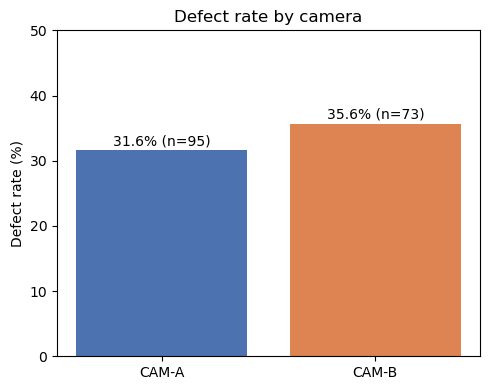

In [24]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(by_cam.index, by_cam["defect_rate"] * 100, color=["#4C72B0", "#DD8452"])
for bar, (_, r) in zip(bars, by_cam.iterrows()):
    label = f"{r['defect_rate']*100:.1f}% (n={int(r['n_images'])})"
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, label, ha="center")
ax.set_ylabel("Defect rate (%)")
ax.set_title("Defect rate by camera")
ax.set_ylim(0, 50)
plt.tight_layout()
plt.show()

## 3. Chart and finding

In [25]:
# Defect rate for other splits, to see which factor matters
for col in ["shift", "exposure_setting"]:
    display(train.groupby(["camera", col])["inspector_label"]
            .agg(n_images="count", defect_rate="mean").round(3))

n_images  defect_rate
camera shift                       
CAM-A  DAY          46        0.283
       NIGHT        49        0.347
CAM-B  DAY          36        0.361
       NIGHT        37        0.351

n_images  defect_rate
camera exposure_setting                       
CAM-A  AUTO                    65        0.292
       NORMAL                  30        0.367
CAM-B  AUTO                    15        0.333
       LOW                     48        0.375
       NORMAL                  10        0.300

I checked day/night and the exposure setting for each camera. The differences are small and mostly stay between 25% and 40%, so neither one explains the defect rate well. The line is more interesting, so I look at it next.

## 3. Defect types by line

inspector_type,edge_chip,missing_hole,scratch,stain
line,,,,
LINE-1,4,4,9,12
LINE-2,10,5,4,8


inspector_type,edge_chip,missing_hole,scratch,stain
line,,,,
LINE-1,13.8,13.8,31.0,41.4
LINE-2,37.0,18.5,14.8,29.6


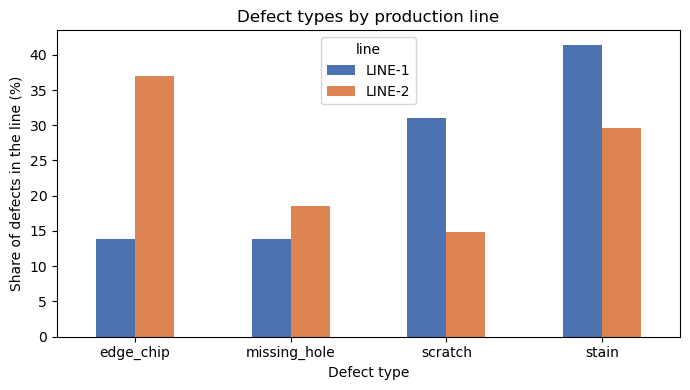

In [26]:
defective = train[train["inspector_label"] == 1]
types = pd.crosstab(defective["line"], defective["inspector_type"])
display(types)
types_pct = (types.div(types.sum(axis=1), axis=0) * 100).round(1)
display(types_pct)

ax = types_pct.T.plot(kind="bar", figsize=(7, 4), color=["#4C72B0", "#DD8452"])
ax.set_ylabel("Share of defects in the line (%)")
ax.set_xlabel("Defect type")
ax.set_title("Defect types by production line")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:** The lines have different kinds of defects. LINE-1 has mostly surface defects: stains and scratches are 21 of its 29 defects (72.4%), with 12 stains and 9 scratches. LINE-2 has about 2.5 times more edge chips (10 cases against 4 in LINE-1), and edge chips are 37.0% of the defects in LINE-2.